

#  DICOM to NIfTI Conversion

We converted the Duke Breast MRI data from DICOM format (as provided by TCIA) into 3D NIfTI files. Although a mapping file was originally available on the Duke website, it was outdated. We therefore generated an updated mapping and provide the code for its application below.



In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import struct
import os

## Dicom utils

In [19]:
import os
import pydicom
import numpy as np
import pandas as pd

def read_dicom_series(folder_path):
    """
    Read DICOM series from a given folder

    Args:
    folder_path (str): Path to the folder containing DICOM files

    Returns:
    tuple: (numpy array of DICOM images, first DICOM file for metadata)
    """
    # Get all DICOM files in the folder
    dcm_files = [f for f in os.listdir(folder_path) if f.endswith('.dcm')]

    # Sort files to ensure correct order
    dcm_files.sort(key=lambda x: int(x.split('-')[-1].split('.')[0]))

    # Read DICOM files
    dicom_images = []
    for dcm_file in dcm_files:
        full_path = os.path.join(folder_path, dcm_file)
        dicom_image = pydicom.dcmread(full_path)
        dicom_images.append(dicom_image.pixel_array)

    # Convert to numpy array
    dicom_stack = np.array(dicom_images)

    return dicom_stack, dicom_image

In [20]:
import os
import pydicom
import numpy as np
import pandas as pd

def read_dicom_series_positions(folder_path):
    """
    Read DICOM series from a given folder

    Args:
    folder_path (str): Path to the folder containing DICOM files

    Returns:
    tuple: (numpy array of DICOM images, first DICOM file for metadata)
    """
    # Get all DICOM files in the folder
    dcm_files = [f for f in os.listdir(folder_path) if f.endswith('.dcm')]

    # Sort files to ensure correct order
    dcm_files.sort(key=lambda x: int(x.split('-')[-1].split('.')[0]))

    # Read DICOM files
    dcm=[]
    for dcm_file in dcm_files:
        full_path = os.path.join(folder_path, dcm_file)
        dicom_image = pydicom.dcmread(full_path)
        dcm.append(dicom_image)


    return dcm

In [21]:
def extract_voxel_sizes(dicom_image):
    """
    Extract voxel sizes from DICOM metadata

    Args:
    dicom_image (pydicom.dataset.FileDataset): DICOM image file

    Returns:
    dict: Voxel sizes in x, y, z directions
    """
    try:
        # Pixel spacing (x, y)
        pixel_spacing = dicom_image.PixelSpacing

        # Slice thickness (z)
        slice_thickness = dicom_image.SliceThickness if hasattr(dicom_image, 'SliceThickness') else None

        return {
            'voxel_x': float(pixel_spacing[0]),
            'voxel_y': float(pixel_spacing[1]),
            'voxel_z': float(slice_thickness) if slice_thickness is not None else None
        }
    except Exception as e:
        print(f"Error extracting voxel sizes: {e}")
        return {
            'voxel_x': None,
            'voxel_y': None,
            'voxel_z': None
        }

# Path setup

In [41]:
my_computer=True
my_colab=False

git_samples=False

base_path = "..\..\BreastDCEDL"

In [43]:
# use if data nifti data is downloaded
if my_computer:
    # Directory where the nifti data will be places
    base_path = "G:\\My Drive\\breast_mri"
    nifti_path= {'spy2':os.path.join(base_path,"SPY2","vis1","dce"),
                        'spy1':os.path.join(base_path,"SPY1","vis1","dce"),
                        'duke':os.path.join(base_path,"DUKE","dce")}

    mask_path={'spy2':os.path.join(base_path,"SPY2","vis1","mask"),
                    'spy1':os.path.join(base_path,"SPY1","vis1","mask"),
                    'duke':os.path.join(base_path,"DUKE","mask")}
    # Directory where original dicom files are
    
    
# use for data_samples
if git_samples:
    base_path = os.path.abspath('../')
    nifti_path= {'spy2':os.path.join(base_path,"SPY2","data_samples","dce"),
                        'spy1':os.path.join(base_path,"SPY1","data_samples","dce"),
                        'duke':os.path.join(base_path,"DUKE","data_samples","dce")}

    mask_path={'spy2':os.path.join(base_path,"SPY2","data_samples","mask"),
                    'spy1':os.path.join(base_path,"SPY1","data_samples","mask"),
                    'duke':os.path.join(base_path,"DUKE","data_samples")}
    
    


In [60]:
# input sample dicom files location, 

if git_samples:
    dcm_path=os.path.join(base_path,"DUKE","data_samples","dicom_tcia")
else:
    dcm_path="E:\duke\data\manifest-1607053360376\\Duke-Breast-Cancer-MRI\\"
    dcm_path="..\\..\\breast_mri\\duke\\dicom\\manifest-1747775619870\\Duke-Breast-Cancer-MRI"

In [61]:
os.listdir(dcm_path)[:5]

['Breast_MRI_700',
 'Breast_MRI_728',
 'Breast_MRI_801',
 'Breast_MRI_893',
 'LICENSE']

In [44]:
import os, sys
sys.path.append(os.path.abspath(os.path.join('../', 'utils')))
sys.path.append(os.path.abspath(os.path.join('../', 'utils')))

import data_utils as ds

ds.setup_paths(base_path, nifti_path, mask_path)

{'spy2': 'G:\\My Drive\\breast_mri\\SPY2\\vis1\\dce', 'spy1': 'G:\\My Drive\\breast_mri\\SPY1\\vis1\\dce', 'duke': 'G:\\My Drive\\breast_mri\\DUKE\\dce'} {'spy2': 'G:\\My Drive\\breast_mri\\SPY2\\vis1\\mask', 'spy1': 'G:\\My Drive\\breast_mri\\SPY1\\vis1\\mask', 'duke': 'G:\\My Drive\\breast_mri\\DUKE\\mask'}


In [53]:
df = pd.read_csv('duke_dicom_nifti_mapping.csv')

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 22 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pid           920 non-null    object 
 1   n_tp          920 non-null    int64  
 2   n_xy          920 non-null    int64  
 3   n_z           920 non-null    int64  
 4   slice_space   920 non-null    float64
 5   voxel_x       920 non-null    float64
 6   voxel_z       920 non-null    float64
 7   top_folder    920 non-null    object 
 8   file_count    920 non-null    float64
 9   t1_file       920 non-null    object 
 10  acq0          920 non-null    object 
 11  acq1          920 non-null    object 
 12  acq2          920 non-null    object 
 13  acq3          913 non-null    object 
 14  acq4          433 non-null    object 
 15  sraw          916 non-null    float64
 16  eraw          916 non-null    float64
 17  scol          916 non-null    float64
 18  ecol          916 non-null    

# Convert Dicom slices to 3D arrays
## * importent point: slice thickness from metadata differ voxel_z, we chose voxel_z.

In [47]:
dcm_path

'..\\..\\breast_mri\\duke\\dicom\\'

In [48]:
# setup output path for nifti files
!mkdir duke_nifti
output_nifti_path = './duke_nifti'

In [81]:


    for i, row in df.iterrows():
        
        pid =  row['pid']
        if pid not in os.listdir(dcm_path): continue
            
        print(i, '---',pid)
        acq=[]

        last_id = int(row['n_tp']-1)

        for k in range(5):

                acq_col='acq'+str(k)
                
                
                if pd.isna(row[acq_col]):
                    
                    continue

                
                folder_path = os.path.join(dcm_path,
                                           row['pid'],
                                           row['top_folder'],
                                           row[acq_col])
                if not os.path.isdir(folder_path):
                    
                    if k<5: print('=====Not enought Acquisitions',k, folder_path,acq_col)
                    continue
                    print('=====Finnished',k-1, ' Acquisitions')

                # Read DICOM series
                dicom_stack, first_dicom = read_dicom_series(folder_path)

                # we exctracted this information and saved it in the mapping file
                #voxel_sizes = extract_voxel_sizes(first_dicom)
            
                # Validate shape
                assert(row['n_xy'] == first_dicom.Rows)
                assert(row['n_xy'] == first_dicom.Columns)
                assert(row['n_z'] == dicom_stack.shape[0])
                
                fn = pid+'_duke_aqc_'+str(k)+'.nii.gz'
                save_nifti(os.path.join(output_nifti_path, fn),dicom_stack)
                
        


890 --- Breast_MRI_893
{'voxel_x': 0.80357140302658, 'voxel_y': 0.80357140302658, 'voxel_z': 1.2000000476837}


# Visualize created niftii and tumor bounding box

In [101]:
df[df.pid.isin(os.listdir(dcm_path))].head()

,pid,n_tp,n_xy,n_z,slice_space,voxel_x,voxel_z,top_folder,file_count,t1_file,...,acq2,acq3,acq4,sraw,eraw,scol,ecol,mask_start,mask_end,acq0_increas
697,Breast_MRI_700,3,448,176,2.0,0.758929,1.0,01-01-1990-NA-BREASTROUTINE DYNAMICS-25367,4.0,2.000000-ax t1-15371,...,12.000000-ax dyn 3rd pass-48141,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
725,Breast_MRI_728,3,448,208,2.0,0.781250,1.0,01-01-1990-NA-BREASTROUTINE-53543,4.0,2.000000-ax 3d t1 bilateral-61594,...,10.000000-ax dyn 2nd pass-67658,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
798,Breast_MRI_801,3,448,208,2.0,0.803571,1.2,01-01-1990-NA-BREASTROUTINE-21293,4.0,2.000000-ax 3d t1 bilateral-47597,...,9.000000-ax dyn 2nd pass-55694,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
890,Breast_MRI_893,3,448,160,1.2,0.803571,1.2,01-01-1990-NA-MRI BREAST BILATERAL WWO-90843,4.0,4.000000-ax t1 tse-23768,...,10.000000-ax dyn 2nd pass-14122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [14]:

r=df.iloc[0]
pid=r['pid']
print(pid)
a0=ds.get_nifti_acquisition(pid, idx=0)
a1=ds.get_nifti_acquisition(pid, idx=1)
a2=ds.get_nifti_acquisition(pid, idx=r['n_tp']-1) # last acqisition

Breast_MRI_001


<Figure size 640x480 with 0 Axes>

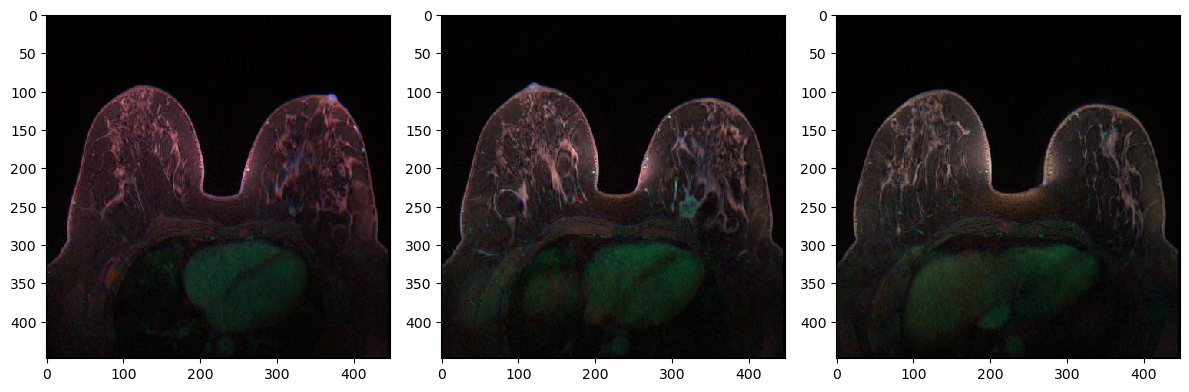

In [105]:
idx=[startm+1, (startm+endm)//2,endm-1]
ds.show_n_images([ds.to_rgb(a0[k],a1[k],a2[k]) for k in idx], axis_off=False)

